# 01 · Loading data files

Try `stk.load()` on our files. Every load prints what it read and anything it assumed.

To try your own file, change the path in any cell and run it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import spectrum_toolkit as stk

## 1. One spectrum from a text file

In [2]:
s = stk.load('../data/CV+RhB+MB_data cliped from 1600 to 1700.xlsx')
s

Loaded CV+RhB+MB_data cliped from 1600 to 1700.xlsx: 35 spectra, 40 points each, x 1600.19 to 1699.03
  - 70 columns read as 35 x/y pairs (one spectrum per pair).
  - x was descending; reversed to ascending order.
  - All pairs share the same x values; combined into one collection.


SpectrumCollection(35 spectra × 40 points, x 1600.19 to 1699.03)

AttributeError: 'SpectrumCollection' object has no attribute 'y'

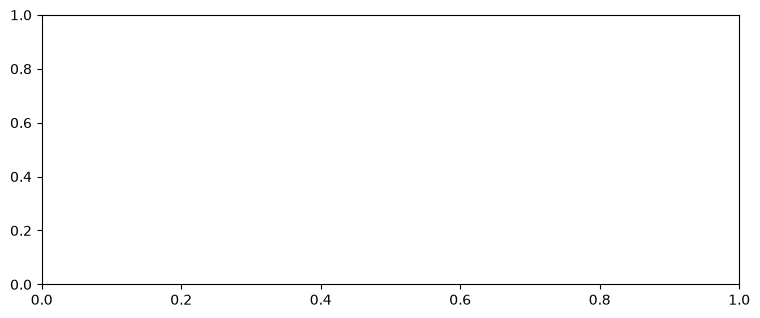

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(s.x, s.y, lw=1)
ax.set_xlabel(s.x_unit or 'x'); ax.set_ylabel(s.y_unit or 'y'); ax.set_title(s.name)
plt.show()

## 2. Several spectra from Excel (x/y pairs)

`MB 10-4M.xlsx` has 5 samples side by side. They share one x axis, so they come back as a `SpectrumCollection`. Names come from the "Sample" row.

In [4]:
c = stk.load('../data/MB 10-4M.xlsx')
c

Loaded MB 10-4M.xlsx: 5 spectra, 1425 points each, x 102.199 to 1802.95
  - Ignored 1 empty column(s): [1].
  - 10 columns read as 5 x/y pairs (one spectrum per pair).
  - x was descending; reversed to ascending order.
  - All pairs share the same x values; combined into one collection.


SpectrumCollection(5 spectra × 1425 points, x 102.199 to 1802.95)

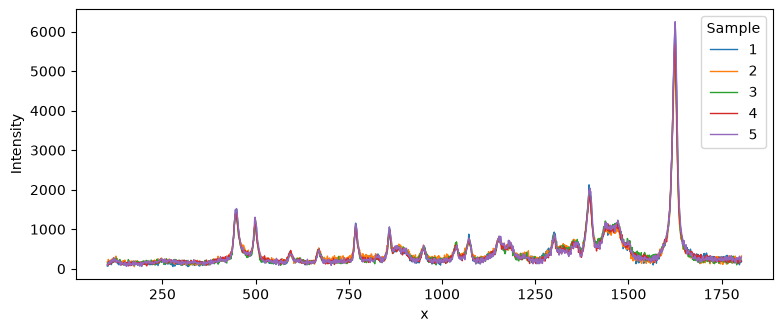

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for sp in c:                     # loop over the 5 spectra
    ax.plot(sp.x, sp.y, lw=1, label=sp.name)
ax.set_xlabel('x'); ax.set_ylabel('Intensity'); ax.legend(title='Sample')
plt.show()

## 3. What was read and assumed

Everything the loader noticed is kept with the data.

In [6]:
c.meta['load_notes']

['Ignored 1 empty column(s): [1].',
 '10 columns read as 5 x/y pairs (one spectrum per pair).',
 'x was descending; reversed to ascending order.',
 'All pairs share the same x values; combined into one collection.']

In [7]:
# One spectrum out of the collection (0 = first)
c[2]

Spectrum('3', 1425 points, x 102.199 to 1802.95, steps: none)

## 4. Overriding the guesses

If the loader reads a file the wrong way, say what you want:

- `sheet='Data'` or `sheet=2`: which sheet (Excel)
- `x_col=1, y_cols=[3]`: which columns (1 = first column; `x_col=0` = point number)
- `layout='pairs'` / `'shared'` / `'xy'`: how columns are arranged
- `delimiter='tab'`, `decimal=','`: text files

In [8]:
# Example: only sample 3, i.e. file columns 6 (x) and 7 (y); column 1 is the empty 'Sample' column
one = stk.load('../data/MB 10-4M.xlsx', x_col=6, y_cols=[7])
one

Loaded MB 10-4M.xlsx: 1 spectrum, 1425 points, x 102.199 to 1802.95
  - Ignored 1 empty column(s): [1].
  - Columns chosen by hand: x = 6, y = [7].
  - x was descending; reversed to ascending order.


Spectrum('MB 10-4M', 1425 points, x 102.199 to 1802.95, steps: none)